# CBSE Grades 4–10 Learning Analytics for personalized education


### Introduction

The rapid growth of digital learning platforms has generated vast amounts of student assessment data, creating opportunities to personalize learning experiences. Traditional curriculum sequencing often assumes that all concepts within a grade level have similar difficulty, whereas students exhibit varying levels of understanding across topics.

This project develops a data-driven educational analytics framework to dynamically classify curriculum concepts into Easy (L1), Medium (L2), and Hard (L3) categories using historical student assessment data. By leveraging unsupervised machine learning techniques, the framework identifies concept difficulty based on actual student performance rather than predefined assumptions.

The analysis uses multiple learning indicators, including student accuracy, incorrect attempts, unattempted questions, and average solving time, collected over eight months. Hierarchical clustering is applied to group concepts with similar learning patterns, enabling adaptive learning strategies that recommend personalized practice paths for students.

### Project Objectives

The primary objectives of this project are:

Develop an analytics framework to measure curriculum concept difficulty using historical assessment data.
Classify CBSE curriculum concepts for Grades 4–10 into Easy (L1), Medium (L2), and Hard (L3).
Identify hidden learning patterns using Hierarchical Clustering.
Evaluate the importance of assessment metrics.
Provide actionable insights that help educators personalize learning paths and optimize curriculum planning.

### Raw Dataset Description

The dataset contains concept-level assessment performance collected from an online learning platform over multiple months. Each record represents the aggregated performance of students for a particular curriculum concept during a given month.

| Feature                            | Description                                                                 |
| ---------------------------------- | --------------------------------------------------------------------------- |
| **Month**                          | Assessment month used for longitudinal analysis (January–August).           |
| **Grade**                          | Student grade level (Grade 4–10).                                           |
| **Subject**                        | Academic subject (Mathematics, Science, English).                           |
| **Chapter_Name**                   | Chapter from the CBSE curriculum.                                           |
| **Concept_Name**                   | Individual learning concept within the chapter.                             |
| **Students_Appeared**              | Number of students who attempted assessments for the concept.               |
| **Correct_Attempts**               | Total correctly answered questions.                                         |
| **Incorrect_Attempts**             | Total incorrectly answered questions.                                       |
| **Unattempted**                    | Questions skipped or left unanswered.                                       |
| **Accuracy (%)**                   | Percentage of correct responses among attempted questions.                  |
| **Incorrect Rate (%)**             | Percentage of incorrect responses.                                          |
| **Unattempted Rate (%)**           | Percentage of skipped questions.                                            |
| **Average Solving Time (Seconds)** | Average time students spent solving questions related to the concept.       |
| **Difficulty Label**               | Cluster assigned by the model (L1, L2, L3). *(Generated after clustering.)* |


In [1]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage,dendrogram,cophenet
from scipy.spatial.distance import pdist
from scipy.stats import f_oneway
import matplotlib.pyplot as plt




In [2]:
df=pd.read_excel('CBSE_Adaptive_Learning_Dataset_Updated.xlsx')
df.head()

,grade,subject,chapter,concept,month,correct_pct,incorrect_pct,unattempted_pct,avg_time_sec,actual_level
0,4,Maths,Numbers,Place Value,2025-01,77,12,11,85,L1
1,4,Maths,Numbers,Place Value,2025-02,71,28,1,105,L2
2,4,Maths,Numbers,Place Value,2025-03,74,16,10,75,L2
3,4,Maths,Numbers,Place Value,2025-04,74,10,16,85,L2
4,4,Maths,Numbers,Place Value,2025-05,80,15,5,75,L1


<div class="alert alert-block alert-warning" style="border-left: 5px solid #ffcc00;">
    <strong>⚠️ Disclaimer:</strong> This is a prototype designed to showcase the approach to a learning analytics business problem. The data used to demonstrate this prototype is entirely randomly generated and does not represent actual industrial data.
</div>


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 464 entries, 0 to 463
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   grade            464 non-null    int64 
 1   subject          464 non-null    object
 2   chapter          464 non-null    object
 3   concept          464 non-null    object
 4   month            464 non-null    object
 5   correct_pct      464 non-null    int64 
 6   incorrect_pct    464 non-null    int64 
 7   unattempted_pct  464 non-null    int64 
 8   avg_time_sec     464 non-null    int64 
 9   actual_level     464 non-null    object
dtypes: int64(5), object(5)
memory usage: 36.4+ KB


In [4]:
df['actual_level'].value_counts(normalize=True)

actual_level
L2    0.706897
L1    0.161638
L3    0.131466
Name: proportion, dtype: float64

### Case 1: Considering raw features

##### Emcoding and Scaling

In [5]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

In [6]:
df['actual_level'] = le.fit_transform(df['actual_level'].astype(str))

In [7]:
print(le.classes_)

['L1' 'L2' 'L3']


In [8]:
features = ['correct_pct', 'incorrect_pct', 'unattempted_pct', 'avg_time_sec','actual_level']


In [9]:
# Initiating scaler
scaler = StandardScaler()

In [10]:
scaler.fit(df[features])

,copy,True
,with_mean,True
,with_std,True


In [11]:
# Viewing the calculated Metrics

metrics_df = pd.DataFrame({
    'Feature': features,
    'Mean (μ)': scaler.mean_,
    'Std Deviation (σ)': scaler.scale_  
})
print("--- Calculated Scaling Metrics ---")
print(metrics_df.to_string(index=False))

--- Calculated Scaling Metrics ---
        Feature   Mean (μ)  Std Deviation (σ)
    correct_pct  66.101293           9.312376
  incorrect_pct  21.484914           5.229619
unattempted_pct  12.898707           8.915581
   avg_time_sec 113.974138          22.719034
   actual_level   0.969828           0.540549


In [12]:
X = scaler.transform(df[features])


In [13]:
X

array([[ 1.17034655, -1.81369132, -0.21296502, -1.27532438, -1.79415341],
       [ 0.52604266,  1.24580524, -1.33459692, -0.39500526,  0.05581811],
       [ 0.8481946 , -1.04881718, -0.32512821, -1.71548394,  0.05581811],
       ...,
       [-0.22564522, -0.66638011,  0.5721773 ,  0.52932982,  0.05581811],
       [-1.72902098,  1.0545867 ,  1.13299325,  0.61736173,  1.90578962],
       [-0.76256513,  1.0545867 ,  0.12352455,  0.7494096 ,  0.05581811]],
      shape=(464, 5))

##### K-means

In [14]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

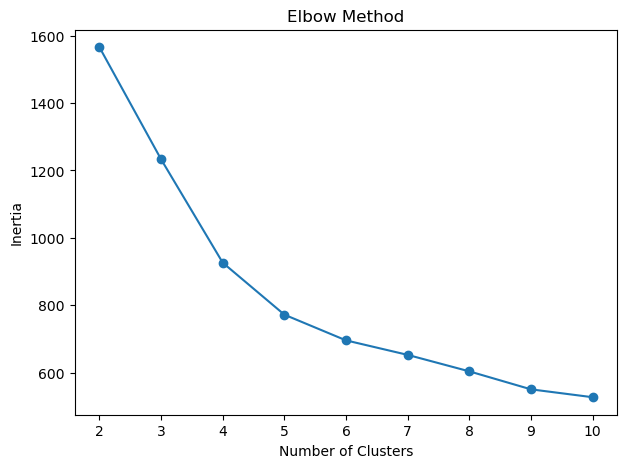

In [15]:
inertia = []

for k in range(2,11):
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(X)
    inertia.append(km.inertia_)

plt.figure(figsize=(7,5))
plt.plot(range(2,11), inertia, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

According to elbow method, drop in WCSS (within cluster sum of squares of error) is not significant after cluster 4. 

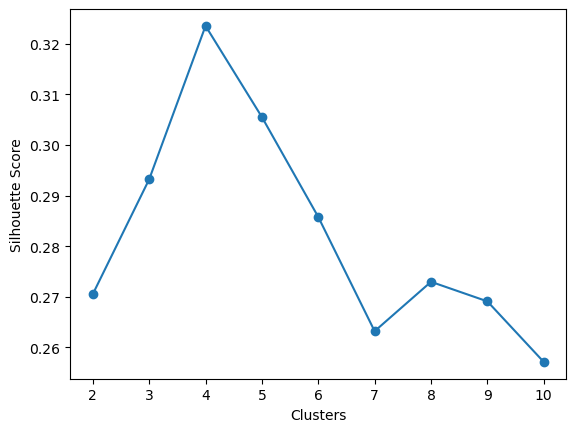

In [16]:
from sklearn.metrics import silhouette_score

scores = []

for k in range(2,11):
    km = KMeans(n_clusters=k, random_state=42)
    labels = km.fit_predict(X)
    scores.append(silhouette_score(X, labels))

plt.plot(range(2,11), scores, marker='o')
plt.xlabel("Clusters")
plt.ylabel("Silhouette Score")
plt.show()

Silhouette score is considerablely higher for 4 clusters.

##### Hierarchical clustering

In [17]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

import pandas as pd

linkages = ['ward', 'complete', 'average', 'single']
cluster_range = range(2, 7)   # Test 2 to 6 clusters

results = []

for n_clusters in cluster_range:

    for linkage in linkages:

        # Ward only supports Euclidean distance
        if linkage == 'ward':
            model = AgglomerativeClustering(
                n_clusters=n_clusters,
                linkage='ward'
            )
        else:
            model = AgglomerativeClustering(
                n_clusters=n_clusters,
                linkage=linkage,
                metric='euclidean'
            )

        labels = model.fit_predict(X)

        # Save cluster labels (optional)
        df[f'{linkage}_{n_clusters}_cluster'] = labels

        # Evaluation metrics
        silhouette = silhouette_score(X, labels)
        db_index = davies_bouldin_score(X, labels)
        ch_index = calinski_harabasz_score(X, labels)

        results.append({
            'Clusters': n_clusters,
            'Linkage': linkage,
            'Silhouette Score': round(silhouette, 4),
            'Davies-Bouldin Index': round(db_index, 4),
            'Calinski-Harabasz Index': round(ch_index, 2)
        })

# Create results dataframe
comparison_df = pd.DataFrame(results)

# Sort by best silhouette score
comparison_df = comparison_df.sort_values(
    by='Silhouette Score',
    ascending=False
).reset_index(drop=True)

comparison_df

,Clusters,Linkage,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,2,average,0.3600,0.9340,168.98
1,2,ward,0.3345,0.9761,176.64
2,2,single,0.3345,0.9761,176.64
3,3,ward,0.3300,1.0335,201.02
4,3,average,0.3300,1.0335,201.02
5,3,single,0.3300,1.0335,201.02
6,4,ward,0.3148,1.1507,225.53
7,4,single,0.3090,0.8739,135.92
8,4,average,0.3071,0.9501,137.70
9,5,ward,0.2741,1.1422,211.18


As per the performance metrics in comparison dataframe, hierarchical clustering with 2 or 3 clusters is more suitable for clustering the concepts. To work towards business objective, 2 or 3 clusters can be implemented to label the concepts to proficieny levels L1, L2, and L3.

### Case 2 : Feature enginerring with selective features 

###### Feature Engineering

In [18]:
df['accuracy_ratio']=df['correct_pct']/100

df['engagement_ratio']=(100-df['unattempted_pct'])/100

df['speed_score']=df['correct_pct']/df['avg_time_sec']

In [19]:
features_2 = ['accuracy_ratio', 'incorrect_pct', 'engagement_ratio','speed_score','avg_time_sec']


##### checking correlation

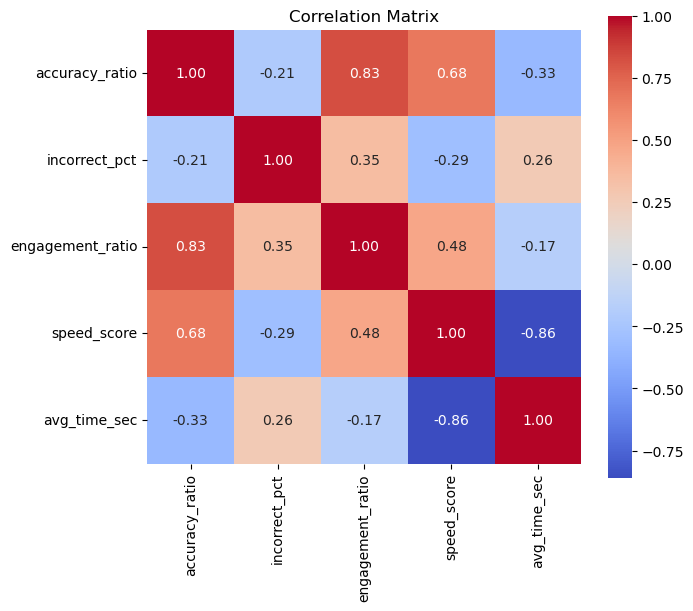

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df[features_2].corr()

plt.figure(figsize=(7,6))
sns.heatmap(corr,
            annot=True,
            cmap='coolwarm',
            fmt='.2f',
            square=True)

plt.title("Correlation Matrix")
plt.show()

Below features are avoided as the were highly correlated with other features.


    1. Actual labels (L1/L2/L3) from previous monthly test analysis are skipped to avoid cascading error / domino effect.
    2. Unattempted percentage was in correaltion with engagement ratio and other features. 

In [21]:
scaler = StandardScaler()
scaler.fit(df[features_2])
# Viewing the calculated Metrics

metrics_df_2 = pd.DataFrame({
    'Feature': features,
    'Mean (μ)': scaler.mean_,
    'Std Deviation (σ)': scaler.scale_  
})
print("--- Calculated Scaling Metrics ---")
print(metrics_df.to_string(index=False))

 	

--- Calculated Scaling Metrics ---
        Feature   Mean (μ)  Std Deviation (σ)
    correct_pct  66.101293           9.312376
  incorrect_pct  21.484914           5.229619
unattempted_pct  12.898707           8.915581
   avg_time_sec 113.974138          22.719034
   actual_level   0.969828           0.540549


In [22]:
X_2 = scaler.transform(df[features_2])

In [54]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

import pandas as pd

linkages = ['ward', 'complete', 'average', 'single']
cluster_range = range(2, 7)   # Test 2 to 6 clusters

results = []

for n_clusters in cluster_range:

    for linkage in linkages:

        # Ward only supports Euclidean distance
        if linkage == 'ward':
            model = AgglomerativeClustering(
                n_clusters=n_clusters,
                linkage='ward'
            )
        else:
            model = AgglomerativeClustering(
                n_clusters=n_clusters,
                linkage=linkage,
                metric='euclidean'
            )

        labels = model.fit_predict(X_2)

        # Save cluster labels (optional)
        df[f'{linkage}_{n_clusters}_cluster'] = labels

        # Evaluation metrics
        silhouette = silhouette_score(X_2, labels)
        db_index = davies_bouldin_score(X_2, labels)
        ch_index = calinski_harabasz_score(X_2, labels)

        results.append({
            'Clusters': n_clusters,
            'Linkage': linkage,
            'Silhouette Score': round(silhouette, 4),
            'Davies-Bouldin Index': round(db_index, 4),
            'Calinski-Harabasz Index': round(ch_index, 2)
        })

# Create results dataframe
comparison_df = pd.DataFrame(results)

# Sort by best silhouette score
comparison_df = comparison_df.sort_values(
    by='Silhouette Score',
    ascending=False
).reset_index(drop=True)

comparison_df

,Clusters,Linkage,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,2,average,0.6608,0.2362,15.30
1,2,single,0.6608,0.2362,15.30
2,3,single,0.4266,0.3403,10.50
3,2,complete,0.4026,0.7757,36.33
4,4,single,0.3609,0.4489,9.97
5,3,average,0.3221,0.6290,28.01
6,2,ward,0.2629,1.3917,198.15
7,3,complete,0.2614,1.1822,142.08
8,5,complete,0.2388,1.1121,140.32
9,4,complete,0.2278,1.1047,134.55


In case of feature engineering, silhouette score is highest for 2 clusters. It is possible to define three proficiency levels by using appropriate weightage to datapoints from two clusters.

In [61]:
print(df["average_2_cluster"].value_counts())

average_2_cluster
0    463
1      1
Name: count, dtype: int64


In [62]:
print(df["single_3_cluster"].value_counts())

single_3_cluster
0    462
1      1
2      1
Name: count, dtype: int64


This clustering does not meet business objective due to their low Calinski-Harabasz Index.
Hence, it is required to find balance between Calinski-Harabasz Index and silhauette score.

In [64]:
# Sort by best Calinski-Harabasz Index
comparison_df = comparison_df.sort_values(
    by='Calinski-Harabasz Index',
    ascending=False
).reset_index(drop=True)

comparison_df

,Clusters,Linkage,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,2,ward,0.2629,1.3917,198.15
1,4,ward,0.2155,1.2304,175.93
2,3,ward,0.2204,1.3179,173.02
3,5,ward,0.2156,1.2158,165.18
4,6,ward,0.1947,1.3077,155.76
5,3,complete,0.2614,1.1822,142.08
6,5,complete,0.2388,1.1121,140.32
7,4,complete,0.2278,1.1047,134.55
8,6,complete,0.2262,0.9525,116.45
9,5,average,0.2089,0.9481,104.70


In [65]:
print(df["ward_2_cluster"].value_counts())

ward_2_cluster
0    239
1    225
Name: count, dtype: int64


##### Checking mean values for different combinations of linkage method and number of clusters.

In [67]:
cluster_profile = (
    df.groupby('ward_2_cluster')[[
        'accuracy_ratio', 'incorrect_pct', 'engagement_ratio','speed_score','avg_time_sec'
    ]]
    .mean()
    .round(2)
)

print(cluster_profile)

                accuracy_ratio  incorrect_pct  engagement_ratio  speed_score  \
ward_2_cluster                                                                 
0                         0.73          22.11              0.94         0.71   
1                         0.59          20.82              0.80         0.51   

                avg_time_sec  
ward_2_cluster                
0                     107.27  
1                     121.09  


In [69]:
cluster_profile = (
    df.groupby('ward_3_cluster')[[
        'accuracy_ratio', 'incorrect_pct', 'engagement_ratio','speed_score','avg_time_sec'
    ]]
    .mean()
    .round(2)
)

print(cluster_profile)

                accuracy_ratio  incorrect_pct  engagement_ratio  speed_score  \
ward_3_cluster                                                                 
0                         0.59          20.82              0.80         0.51   
1                         0.70          24.35              0.94         0.63   
2                         0.78          16.61              0.93         0.90   

                avg_time_sec  
ward_3_cluster                
0                     121.09  
1                     114.31  
2                      89.94  


In [70]:
cluster_profile = (
    df.groupby('complete_3_cluster')[[
        'accuracy_ratio', 'incorrect_pct', 'engagement_ratio','speed_score','avg_time_sec'
    ]]
    .mean()
    .round(2)
)

print(cluster_profile)

                    accuracy_ratio  incorrect_pct  engagement_ratio  \
complete_3_cluster                                                    
0                             0.60          22.96              0.83   
1                             0.84          16.50              0.97   
2                             0.72          20.07              0.91   

                    speed_score  avg_time_sec  
complete_3_cluster                             
0                          0.48        128.04  
1                          1.25         69.75  
2                          0.74        100.37  


Cluster 0 shows concepts with better students average performance.

Cluster 1 shows concepts with poor students average performance.

L1 : Easy : 80 % concepts from cluster 0 and 20 % concepts from cluster 1.

L2 : Moderate : 60 % concepts from cluster 0 and 40 % concepts from cluster 1.

L1 : Hard : 20 % concepts from cluster 0 and 80 % concepts from cluster 1.

#### 2D PCA Scatter Plot of Hierarchical Clusters

##### for ward_2_cluster

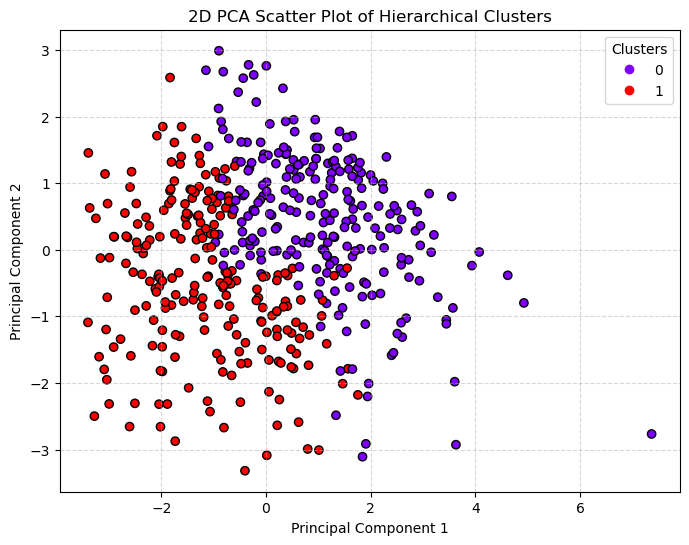

In [66]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# 1. Reduce data dimensions to 2 Principal Components
pca = PCA(n_components=2)
X_2_pca = pca.fit_transform(X_2)

# 2. Plot the reduced dimensions
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_2_pca[:, 0],
    X_2_pca[:, 1],
    c=df["ward_2_cluster"],
    cmap="rainbow",
    edgecolors="k",
)

plt.title("2D PCA Scatter Plot of Hierarchical Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

# Add a legend for the 2 clusters
plt.legend(*scatter.legend_elements(), title="Clusters")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

##### for complete_3_cluster


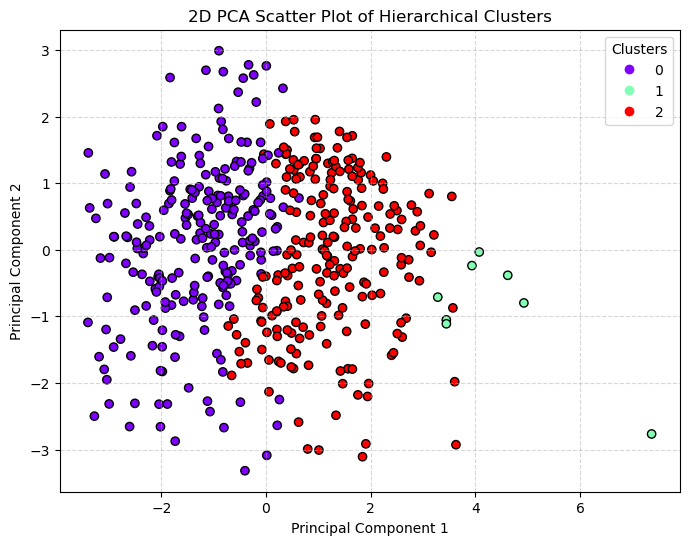

In [74]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# 1. Reduce data dimensions to 2 Principal Components
pca = PCA(n_components=2)
X_2_pca = pca.fit_transform(X_2)

# 2. Plot the reduced dimensions
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_2_pca[:, 0],
    X_2_pca[:, 1],
    c=df["complete_3_cluster"],
    cmap="rainbow",
    edgecolors="k",
)

plt.title("2D PCA Scatter Plot of Hierarchical Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

# Add a legend for the 2 clusters
plt.legend(*scatter.legend_elements(), title="Clusters")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

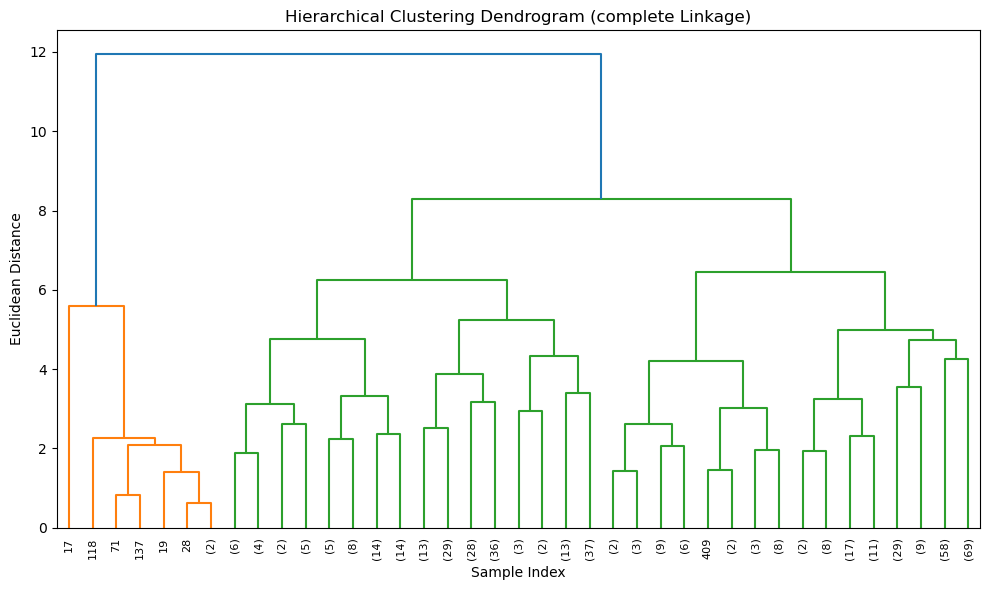

In [72]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage


Z = linkage(X_2, method="complete", metric="euclidean")

# 2. Plot the dendrogram
plt.figure(figsize=(10, 6))
plt.title("Hierarchical Clustering Dendrogram (complete Linkage)")
plt.xlabel("Sample Index")
plt.ylabel("Euclidean Distance")

dendrogram(
    Z,
    truncate_mode="level",
    p=5,  # Adjust p to show more or fewer tree levels
    leaf_rotation=90.0,
)

plt.tight_layout()
plt.show()

### Case 3: PCA

In [75]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

features_3 = [
    'accuracy_ratio',
    'incorrect_pct',
    'engagement_ratio',
    'avg_time_sec',
    'actual_level',
    'speed_score'
]

scaler = StandardScaler()

X_3 = scaler.fit_transform(df[features_3])

# View scaling metrics
metrics_df_3 = pd.DataFrame({
    'Feature': features_3,
    'Mean (μ)': scaler.mean_,
    'Std Deviation (σ)': scaler.scale_
})

print(metrics_df_3)

            Feature    Mean (μ)  Std Deviation (σ)
0    accuracy_ratio    0.661013           0.093124
1     incorrect_pct   21.484914           5.229619
2  engagement_ratio    0.871013           0.089156
3      avg_time_sec  113.974138          22.719034
4      actual_level    0.969828           0.540549
5       speed_score    0.612842           0.192059


In [76]:
from sklearn.decomposition import PCA
import numpy as np

# Retain 95% of variance
pca = PCA(n_components=0.95, random_state=42)

X_pca = pca.fit_transform(X_3)

print(f"Original Features : {X_3.shape[1]}")
print(f"PCA Components    : {X_pca.shape[1]}")
print(f"Variance Retained : {np.sum(pca.explained_variance_ratio_):.4f}")

Original Features : 6
PCA Components    : 3
Variance Retained : 0.9536


In [77]:
variance_df = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(pca.explained_variance_ratio_))],
    'Explained Variance': pca.explained_variance_ratio_,
    'Cumulative Variance': np.cumsum(pca.explained_variance_ratio_)
})

variance_df

,Principal Component,Explained Variance,Cumulative Variance
0,PC1,0.565297,0.565297
1,PC2,0.247747,0.813044
2,PC3,0.140564,0.953607


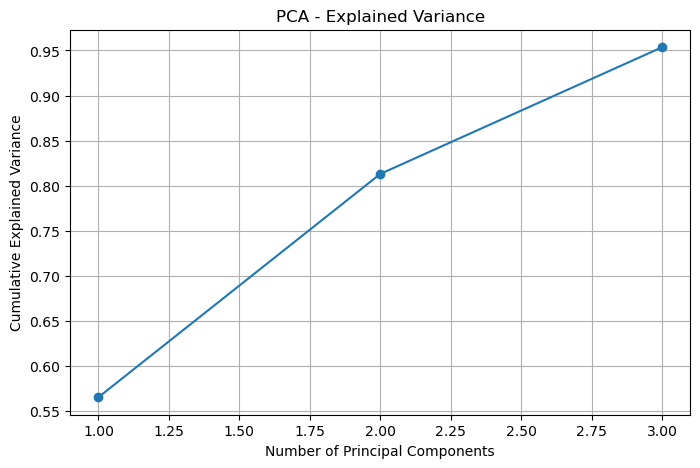

In [78]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(pca.explained_variance_ratio_)+1),
    np.cumsum(pca.explained_variance_ratio_),
    marker='o'
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Explained Variance")
plt.grid(True)

plt.show()

In [79]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

linkages = ['ward', 'complete', 'average', 'single']
cluster_range = range(2,7)

results = []

for n_clusters in cluster_range:

    for linkage in linkages:

        if linkage == 'ward':
            model = AgglomerativeClustering(
                n_clusters=n_clusters,
                linkage='ward'
            )

        else:
            model = AgglomerativeClustering(
                n_clusters=n_clusters,
                linkage=linkage,
                metric='euclidean'
            )

        labels = model.fit_predict(X_pca)

        df[f'PCA_{linkage}_{n_clusters}'] = labels

        results.append({

            'Clusters': n_clusters,

            'Linkage': linkage,

            'Silhouette Score':
                round(silhouette_score(X_pca, labels),4),

            'Davies-Bouldin Index':
                round(davies_bouldin_score(X_pca, labels),4),

            'Calinski-Harabasz Index':
                round(calinski_harabasz_score(X_pca, labels),2)

        })

comparison_pca = pd.DataFrame(results)

comparison_pca = comparison_pca.sort_values(
    by='Silhouette Score',
    ascending=False
).reset_index(drop=True)

comparison_pca

,Clusters,Linkage,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,2,average,0.6152,0.2620,11.96
1,2,single,0.6152,0.2620,11.96
2,3,single,0.3849,0.3722,8.27
3,3,average,0.3347,0.6849,92.35
4,4,ward,0.3110,1.1314,217.30
5,4,average,0.3016,0.8281,140.40
6,2,ward,0.2926,1.3120,218.26
7,4,single,0.2876,0.4275,6.58
8,3,ward,0.2804,1.2478,207.95
9,5,average,0.2766,0.8712,110.10


In [80]:
print(df["PCA_average_2"].value_counts())

PCA_average_2
0    463
1      1
Name: count, dtype: int64


2 clusters with average/single linkage does not show good separation of data points.

In [83]:
print(df["PCA_single_3"].value_counts())

PCA_single_3
0    462
1      1
2      1
Name: count, dtype: int64


In [84]:
print(df["PCA_ward_3"].value_counts())

PCA_ward_3
1    238
0    165
2     61
Name: count, dtype: int64


In [85]:
cluster_profile = (
    df.groupby('ward_3_cluster')[[
        'accuracy_ratio', 'incorrect_pct', 'engagement_ratio','speed_score','avg_time_sec'
    ]]
    .mean()
    .round(2)
)

print(cluster_profile)

                accuracy_ratio  incorrect_pct  engagement_ratio  speed_score  \
ward_3_cluster                                                                 
0                         0.59          20.82              0.80         0.51   
1                         0.70          24.35              0.94         0.63   
2                         0.78          16.61              0.93         0.90   

                avg_time_sec  
ward_3_cluster                
0                     121.09  
1                     114.31  
2                      89.94  


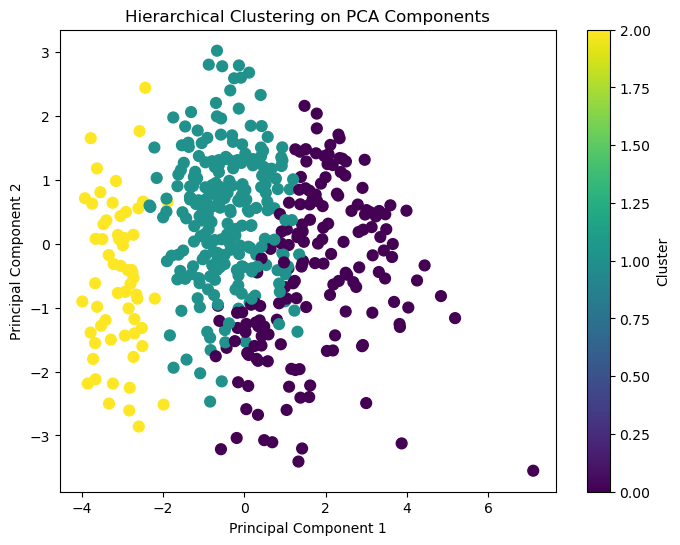

In [86]:
best_labels = df['PCA_ward_3']     

plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=best_labels,
    cmap='viridis',
    s=60
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Hierarchical Clustering on PCA Components")

plt.colorbar(label="Cluster")

plt.show()

###  Clustering Model Comparison


| Model | Clusters | Linkage | Silhouette Score (↑) | Davies-Bouldin Index (↓) | Calinski-Harabasz Index (↑) |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **PCA** | 3 | ward | **0.2804** (Best) | 1.2478 | **207.95** (Best) |
| **Feature_engineering_2** | 3 | complete | 0.2614 | **1.1822** (Best) | 142.08 |
| **Feature_engineering_1** | 2 | ward | 0.2629 | 1.3917 | 198.15 |

### Summary
The **PCA model** is the top performer. It achieves the highest Silhouette Score (0.2804) and Calinski-Harabasz Index (207.95), indicating the best overall cluster separation and variance structure. While Feature_engineering_2 offers slightly tighter, more compact clusters (lowest Davies-Bouldin Index of 1.1822), PCA provides a better balance across all three evaluation metrics.





In [87]:
final_model = AgglomerativeClustering(
                n_clusters=3,
                linkage='ward'
            )

final_labels = final_model.fit_predict(X_pca)

df['Cluster_final'] = final_labels

In [88]:
cluster0 = df[df['Cluster_final'] == 0]
cluster1 = df[df['Cluster_final'] == 1]
cluster2 = df[df['Cluster_final'] == 2]


In [89]:
with pd.ExcelWriter("Clustered_Concepts.xlsx") as writer:
    cluster0.to_excel(writer, sheet_name="Cluster_0", index=False)
    cluster1.to_excel(writer, sheet_name="Cluster_1", index=False)
    cluster2.to_excel(writer, sheet_name="Cluster_2", index=False)


In [90]:
cluster_profile = (
    df.groupby('Cluster_final')[[
    'accuracy_ratio',
    'incorrect_pct',
    'engagement_ratio',
    'avg_time_sec',
    'speed_score'
    ]]
    .mean()
    .round(2)
)

print(cluster_profile)

               accuracy_ratio  incorrect_pct  engagement_ratio  avg_time_sec  \
Cluster_final                                                                  
0                        0.73          19.62              0.91         93.08   
1                        0.65          22.47              0.88        124.54   
2                        0.51          22.67              0.74        129.28   

               speed_score  
Cluster_final               
0                     0.81  
1                     0.53  
2                     0.40  


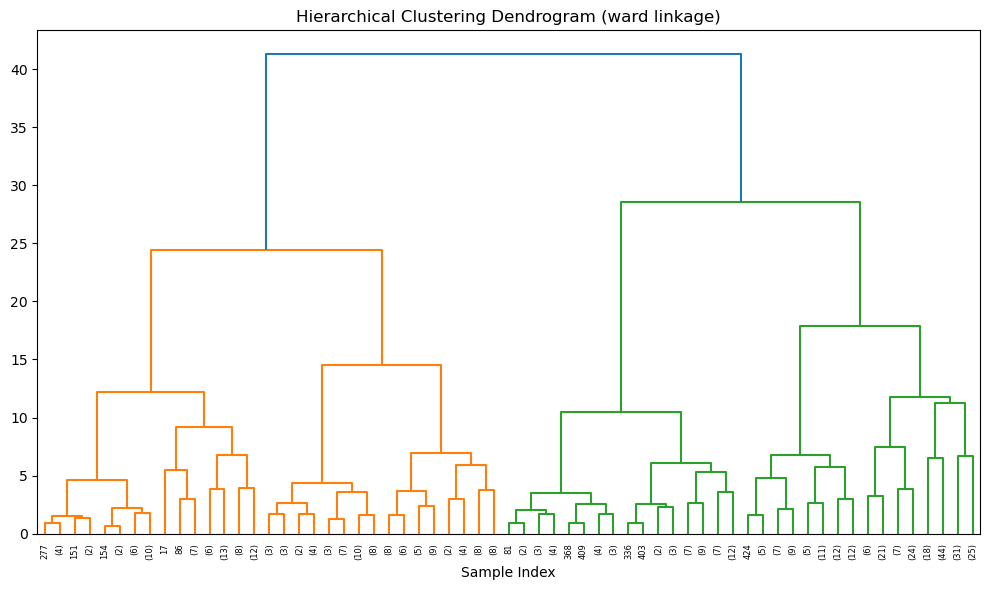

In [91]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage


Z = linkage(X_pca, method="ward")

# 2. Plot the dendrogram
plt.figure(figsize=(10, 6))
plt.title("Hierarchical Clustering Dendrogram (ward linkage)")
plt.xlabel("Sample Index")

dendrogram(
    Z,
    truncate_mode="level",
    p=5,  # Adjust p to show more or fewer tree levels
    leaf_rotation=90.0,
)

plt.tight_layout()
plt.show()


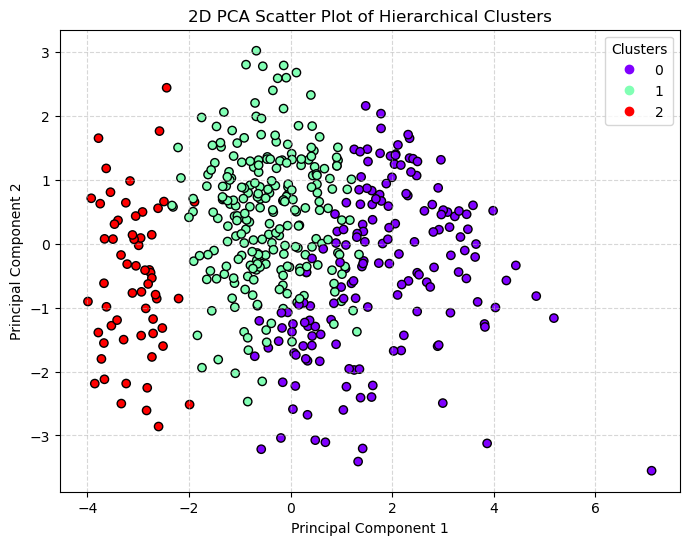

In [92]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA


pca = PCA(n_components=2)
X_2_pca = pca.fit_transform(X_pca)

# 2. Plot the reduced dimensions
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_2_pca[:, 0],
    X_2_pca[:, 1],
    c=df["Cluster_final"],
    cmap="rainbow",
    edgecolors="k",
)

plt.title("2D PCA Scatter Plot of Hierarchical Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

# Add a legend for the 2 clusters
plt.legend(*scatter.legend_elements(), title="Clusters")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


In [93]:
cluster_profile = (
    df.groupby('Cluster_final')[[
    'accuracy_ratio',
    'incorrect_pct',
    'engagement_ratio',
    'avg_time_sec',
    'speed_score'
    ]]
    .mean()
    .round(2)
)

print(cluster_profile)

               accuracy_ratio  incorrect_pct  engagement_ratio  avg_time_sec  \
Cluster_final                                                                  
0                        0.73          19.62              0.91         93.08   
1                        0.65          22.47              0.88        124.54   
2                        0.51          22.67              0.74        129.28   

               speed_score  
Cluster_final               
0                     0.81  
1                     0.53  
2                     0.40  


##### Summerizing three clusters:

###### Cluster 0 Difficulty level (L1) Easy 

-- High accuracy ratio, low incorrect percentage, high engagement ratio, high speed score, low average time





###### Cluster 1 Difficulty level (L2) Medium 

-- Moderate accuracy ratio, high incorrect percentage compared to L1, low engagement ratio compared to L1, moderate speed score, high average time





###### Cluster 0 Difficulty level (L3) Hard 

-- Low accuracy ratio, highest incorrect percentage, lowest engagement ratio, lowest speed score, highest average time


<div class="alert alert-block alert-warning" style="border-left: 5px solid #ffcc00;">
    <strong>⚠️ Disclaimer:</strong> This is a prototype designed to showcase the approach to a learning analytics business problem. The data used to demonstrate this prototype is entirely randomly generated and does not represent actual industrial data.
</div>
